In [1]:
import anndata
from anndata import AnnData
import pandas as pd
import rectanglepy as rp
import matplotlib.pyplot as plt
from scipy.io import mmread
from scipy.sparse import csr_matrix
import helper
# assert version of rectanglepy

# Figure 2

In [2]:
annotations = pd.read_csv('../data/haoSub_annotations.csv', index_col=0)
genes = pd.read_csv('../data/haoSub_genes.csv', index_col=0)
counts = mmread('../data/haoSub_counts.mtx')
counts = pd.DataFrame(counts.todense())
counts = counts.T
counts.columns = genes['x']

In [3]:
adata_hao_sub = AnnData(counts, obs=annotations)

/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [4]:
# write adata to file
adata_hao_sub.write_h5ad('../data/haoSub_adata.h5ad')

In [5]:
adata_hao_sub = anndata.read_h5ad('../data/haoSub_adata.h5ad')

In [6]:
sc_data_muris = pd.read_pickle("../data/sc_data_tabula_muris.pkl")
annotations = pd.read_csv("../data/annotations_tabula_muris.csv", index_col=0)
annotations = annotations['0']
annotations = pd.Series(annotations, index=sc_data_muris.columns)
adata_muris = AnnData(sc_data_muris.T, obs=annotations.to_frame(name="cell_type"))

## Figure 2A

In [7]:
# Load Bulks
bulks_chen = pd.read_csv("../data/bulks_chen_tpm.csv", index_col=0)
bulks_peti = pd.read_csv("../data/bulks_petitprez_tpm.csv", index_col=0)
bulks_fino = pd.read_csv("../data/fig2/finotello/bulks_finotello_tpm.csv", index_col=0)
bulks_hoek = pd.read_csv("../data/bulks_hoek_tpm.csv", index_col=0)
bulks_morandini = pd.read_csv("../data/fig2/morandini/morandini_tpm.csv.gz", index_col=0)
bulks_altman = pd.read_csv("../data/fig2/altman/altman_tpm.csv.gz", index_col=0)



In [8]:
estimations_fino, signature_results_fino = rp.rectangle(adata_hao_sub, bulks_fino.T)


2025-12-23 20:18:19.166 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 12872 common genes between bulks and single-cell data
2025-12-23 20:18:20.980 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-12-23 20:18:23.263 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-12-23 20:18:25.126 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2025-12-23 20:18:26.091 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2025-12-23 20:18:27.161 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-12-23 20:18:27.886 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2025-12-23 20:18:28.486 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2025-12-23

solved 75 -15588360.860132977
solved 125 -38414463.770311534
solved 175 -18246160.599037617
solved 200 -32094951.76616158
solved 125 -13397825.452522755
solved 75 -31024147.85268208
solved 150 -24792998.506202098
solved 175 -22259176.22361004
solved 150 -49516884.53757307
solved 100 -36717136.42896444
solved 200 -47927387.40364246
solved 125 -28283060.918114893
solved 125 -40007464.31801152
solved 200 -70170610.66105579
solved 125 -24928294.764478516
solved 225 -25458325.822325476
solved 75 -14710404.49501788
solved 175 -30712115.59884495
solved 75 -24545424.553370453
solved 150 -44435113.095440075
solved 75 -28939960.036446422
solved 125 -28487651.96133528
solved 200 -40220655.91948034
solved 125 -17711680.662424125
solved 125 -17911006.680214282
solved 125 -27170926.916297726
solved 175 -35848301.13779822
solved 150 -32514719.36068127
solved 150 -21268029.0146305
solved 100 -34942939.650001645
solved 175 -35662224.423787944
solved 100 -48907775.24602342
solved 100 -14341588.477524469

2025-12-23 20:18:34.524 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:416 - RMSE:0.03419098237210253, Pearson R:0.8646498149362342 for p=0.05, lfc=1.7
2025-12-23 20:18:34.611 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 79


solved 200 -69991923.48060179
solved 125 -24794976.434275996
solved 225 -25364922.790856156
solved 75 -14629117.774950966
solved 250 -30585402.95618437
solved 75 -24465088.964389406
solved 150 -44304956.24629962
solved 75 -28821062.285913836
solved 125 -28386517.571089968
solved 225 -40114218.853834316
solved 175 -17611969.420455523
solved 125 -17808550.128102154
solved 125 -27055037.15337473
solved 275 -35696173.34782732
solved 150 -32392163.650234662
solved 125 -21124191.128737975
solved 75 -34829041.77104802
solved 200 -35538647.163476095
solved 125 -48808266.512160644
solved 125 -14251076.144905766
solved 225 -29198381.656312082
solved 75 -25259410.52683934
solved 125 -21107609.536796555
solved 125 -36396085.620959386
solved 150 -45517391.45046601
solved 125 -42266086.9453595
solved 125 -36680586.99370825
solved 125 -31457495.193497494
solved 75 -49015120.83276437
solved 200 -27101148.865814354
solved 175 -27450869.99155509
solved 100 -39177876.60279732
solved 100 -43233436.3445497

2025-12-23 20:18:34.751 | INFO     | rectanglepy.pp.create_signature:_optimize_parameters:416 - RMSE:0.03500977011006541, Pearson R:0.8579565887787929 for p=0.05, lfc=1.8
2025-12-23 20:18:34.821 | INFO     | rectanglepy.pp.create_signature:_get_marker_genes:225 - Optimal condition number: 79


...

2025-12-23 20:18:54.506 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:237 - Finished deconvolution for bulk: 5


solved 100 -20781682861.50708
solved 75 -18112979342.65155
solved 75 -17568295862.45777
solved 75 -17328286462.94265
solved 75 -17191042179.14556
solved 75 -17068633357.071869
solved 75 -16936628247.174469
solved 75 -16844409741.73625
solved 75 -16776163106.335737
solved 75 -16723508732.116802
solved 75 -16678298673.87024
solved 75 -16635932458.273468
solved 75 -16601277198.903028
solved 100 -12211397624.783873
solved 100 -12789015679.157026
solved 100 -13219664472.044926
solved 100 -13491328948.10632
solved 100 -13670148088.169516
solved 100 -13802455989.433842
solved 100 -13903845362.823263
solved 100 -13985450955.608181
solved 100 -14052796428.975344
solved 100 -14109497536.99725
solved 100 -14158725867.860039
solved 100 -14201300405.25481
solved 100 -14238504172.06974
solved 125 -84780983.0313729


2025-12-23 20:18:54.876 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:237 - Finished deconvolution for bulk: 6


solved 75 -10059909957.122896
solved 75 -8554227762.052785
solved 75 -8104765651.332707
solved 75 -7886183496.642545
solved 75 -7756132186.756266
solved 75 -7669859363.382144
solved 75 -7608421512.092579
solved 75 -7562405421.977594
solved 150 -62412934.72737852
solved 100 -12185209999.739222
solved 100 -12788323530.442383
solved 100 -13218551973.845734
solved 100 -13489476536.757923
solved 100 -13668228120.259516
solved 100 -13800728875.467749
solved 100 -13902195266.765232
solved 100 -13983831400.210417
solved 100 -14051226077.75603
solved 100 -14108028582.62485
solved 100 -14157308093.690886
solved 100 -14199913083.092033
solved 100 -14237143570.79974


2025-12-23 20:18:57.644 | INFO     | rectanglepy.tl.deconvolution:_process_bulk:237 - Finished deconvolution for bulk: 8
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/berni/PycharmProjects/rectangle_paper/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [9]:
estimations_fino.to_csv("../output/hao_estimations_fino_sub.csv")

In [10]:
estimations_fino = pd.read_csv("../output/hao_estimations_fino_sub.csv", index_col=0)

In [11]:
finotello_gld = pd.read_csv('../data/finotello_facs.csv', index_col=0).T
finotello_gld = finotello_gld.fillna(0)
finotello_gld.columns = ["NK cells", 'B cells', 'Tregs', 'mDC', 'Monocytes', 'Neutrophilss', 'T cells CD8',
                         'T cells CD4 conv', 'Other']
finotello_gld = finotello_gld.T

<Axes: title={'center': 'Finotello'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

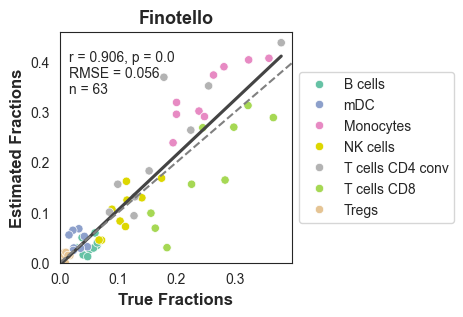

In [12]:
gld_m, finotello_m = helper.match_dfs(finotello_gld, estimations_fino.T)
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
finotello_m = finotello_m.sort_index(key=lambda x: x.str.lower())
evaluation_fintotello_rectangle = helper.create_evaluation_df(gld_m, finotello_m)
rsme_finotello_rectangle, r_finotello_rectangle, p_finotello_rectangle = helper.evaulate_total_df(
    evaluation_fintotello_rectangle)
rsmes_f_rectangle, ps_f_rectangle, rs_f_rectangle = helper.evaluate_by_cell_type(gld_m, finotello_m)
helper.create_scatter_plot_total(evaluation_fintotello_rectangle, rsme_finotello_rectangle, p_finotello_rectangle,
                                 r_finotello_rectangle,
                                 'Finotello', save_path='../figures/fig2a_fino.pdf', size=(3, 3))

In [15]:
estimations_hoek, signature_results_hoek = rp.rectangle(adata_hao_sub, bulks_hoek.T)
estimations_hoek.to_csv("../output/hao_estimations_hoek_sub.csv")

2025-12-23 20:04:55.079 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 12872 common genes between bulks and single-cell data
2025-12-23 20:04:56.907 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-12-23 20:04:59.145 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-12-23 20:05:01.301 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2025-12-23 20:05:02.428 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2025-12-23 20:05:03.635 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-12-23 20:05:04.413 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2025-12-23 20:05:05.155 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2025-12-23

In [17]:
estimations_hoek = pd.read_csv("../output/hao_estimations_hoek_sub.csv", index_col=0)

<Axes: title={'center': 'Hoek'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

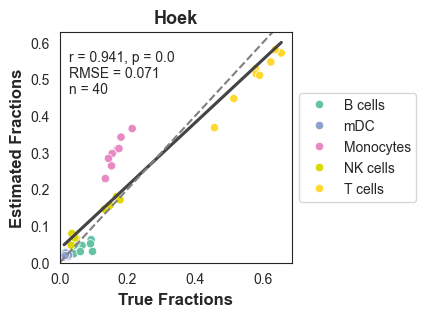

In [18]:
hoek_gld = pd.read_csv('../data/hoek_facs.csv', index_col=0).T
hoek_gld = hoek_gld.fillna(0)
hoek_gld.columns = ["T cells", 'Monocytes', 'B cells', 'mDC', 'NK cells']
hoek_gld = hoek_gld.T


estimations_hoek['T cells'] = estimations_hoek['T cells CD4 conv'] + estimations_hoek['T cells CD8'] + estimations_hoek[
    'Tregs']

estimations_hoek = estimations_hoek.T

gld_hoek_m, hoek_m = helper.match_dfs(hoek_gld, estimations_hoek)
gld_hoek_m = gld_hoek_m.sort_index(key=lambda x: x.str.lower())
hoek_m = hoek_m.sort_index(key=lambda x: x.str.lower())
evaluation_hoek = helper.create_evaluation_df(gld_hoek_m, hoek_m)
rsme_hoek, r_hoek, p_hoek = helper.evaulate_total_df(evaluation_hoek)
rsmes_h, ps_h, rs_h = helper.evaluate_by_cell_type(gld_hoek_m, hoek_m)
helper.create_scatter_plot_total(evaluation_hoek, rsme_hoek, p_hoek, r_hoek, 'Hoek', save_path='../figures/fig2a_hoek.pdf', size=(3, 3))

In [19]:
estimations_chen, signatures_chen  = rp.rectangle(adata_muris, bulks_chen.T)
estimations_chen.to_csv("../output/muris_estimations_chen.csv")

2025-12-23 20:06:31.762 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 10978 common genes between bulks and single-cell data
2025-12-23 20:06:33.019 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-12-23 20:06:34.178 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-12-23 20:06:35.039 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Macrophages
2025-12-23 20:06:35.733 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-12-23 20:06:36.454 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD4 conv
2025-12-23 20:06:37.130 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD8
2025-12-23 20:06:37.912 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Tregs

In [20]:
estimations_chen= pd.read_csv("../output/muris_estimations_chen.csv", index_col=0)

<Axes: title={'center': 'Chen'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

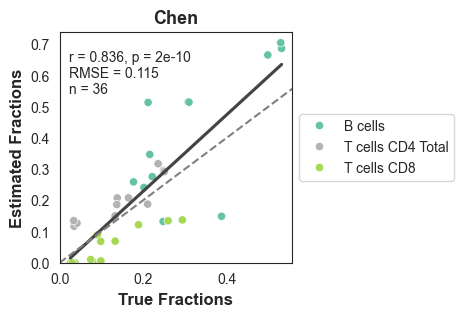

In [21]:
chen_gld = pd.read_csv('../data/chen_facs.csv', index_col=0).T
chen_gld = chen_gld.fillna(0)
chen_gld.columns = ["Monocytes", "B cells", 'T cells CD8', 'T cells CD4 Total']
chen_t = estimations_chen
chen_t['T cells CD4 Total'] = chen_t['T cells CD4 conv'] + chen_t['Tregs']
chen_m, gld_m = helper.match_dfs(chen_t,chen_gld)
# sort alphabetically reverse
gld_m = gld_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
chen_m = chen_m.sort_index(key=lambda x: x.str.lower(), ascending=True)
evaluation_chen = helper.create_evaluation_df(gld_m.T, chen_m.T)
# sort by index alphabetically ignore case
evaluation_chen = evaluation_chen.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_chen, r_chen, p_chen = helper.evaulate_total_df(evaluation_chen)
rsmes_chen, ps_chen, rs_chen = helper.evaluate_by_cell_type(gld_m.T, chen_m.T)

helper.create_scatter_plot_total(evaluation_chen, rsme_chen, p_chen, r_chen, 'Chen', save_path='../figures/fig2a_chen.pdf', size=(3, 3))

In [22]:
estimations_peti, signatures_peti = rp.rectangle(adata_muris, bulks_peti.T)
estimations_peti.to_csv('../output/muris_estimations_peti.csv')

2025-12-23 20:08:29.903 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 10978 common genes between bulks and single-cell data
2025-12-23 20:08:31.112 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-12-23 20:08:32.288 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-12-23 20:08:32.956 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Macrophages
2025-12-23 20:08:33.662 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-12-23 20:08:34.373 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD4 conv
2025-12-23 20:08:35.091 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for T cells CD8
2025-12-23 20:08:35.780 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Tregs

In [23]:
estimations_peti = pd.read_csv('../output/muris_estimations_peti.csv', index_col=0)

<Axes: title={'center': 'Petitprez'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

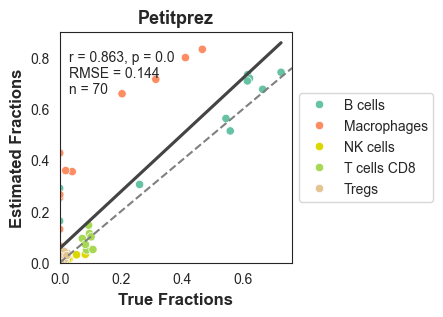

In [24]:
petitprez_gld = pd.read_csv('../data/petitprez_facs.csv', index_col=0).T
petitprez_gld = petitprez_gld.fillna(0)

# replace nan with 0
petitprez_gld = petitprez_gld.fillna(0)

petitprez_gld.columns = ["T cells", 'T cells CD8', 'B cells', 'Tregs', 'NK cells', 'B cells ger', 'Basophils', 'Mast',
                         'Macrophages', 'Eosinophils', 'Neutrophils', 'Monocytes', 'B derived', 'Mono Macro', 'NK_or_T',
                         'Granulocytes']
# drop columns
petitprez_gld = petitprez_gld.drop(['T cells'], axis=1)

# sort by index alphabetically ignore case
petitprez_gld = petitprez_gld.sort_index(key=lambda x: x.str.lower())
estimations_peti = estimations_peti.sort_index(key=lambda x: x.str.lower())


gld_m, petitprez_m = helper.match_dfs(petitprez_gld, estimations_peti)
evaluation_petitprez = helper.create_evaluation_df(gld_m.T, petitprez_m.T)
# sort by index alphabetically ignore case
evaluation_petitprez = evaluation_petitprez.sort_values(by='Cell type', key=lambda x: x.str.lower())
rsme_peptirez, r_peptirez, p_peptirez = helper.evaulate_total_df(evaluation_petitprez)
rsmes_pept, ps_pept, rs_pept = helper.evaluate_by_cell_type(gld_m.T, petitprez_m.T)

helper.create_scatter_plot_total(evaluation_petitprez, rsme_peptirez, p_peptirez, r_peptirez, 'Petitprez',
                                 save_path='../figures/fig2a_petitprez.pdf', size=(3, 3))


In [25]:
estimations_morandini, signatures_morandini = rp.rectangle(adata_hao_sub, bulks_morandini.T)


2025-12-23 20:09:18.293 | INFO     | rectanglepy.pp.create_signature:build_rectangle_signatures:327 - Using 7593 common genes between bulks and single-cell data
2025-12-23 20:09:19.441 | INFO     | rectanglepy.pp.create_signature:_de_analysis:200 - Starting DE analysis
2025-12-23 20:09:20.856 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for B cells
2025-12-23 20:09:21.486 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for ILC
2025-12-23 20:09:22.226 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Monocytes
2025-12-23 20:09:23.007 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for NK cells
2025-12-23 20:09:23.640 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Plasma cells
2025-12-23 20:09:24.240 | INFO     | rectanglepy.pp.create_signature:_run_deseq2:148 - Running DE analysis for Platelet
2025-12-23 

In [ ]:
estimations_morandini.to_csv('../output/hao_estimations_morandini.csv')

In [ ]:
estimations_morandini = pd.read_csv('../output/hao_estimations_morandini.csv', index_col=0).T
estimations_morandini['T cells CD4'] = estimations_morandini['T cells CD4 conv']
estimations_morandini['T cells'] = estimations_morandini['T cells CD4 conv'] + estimations_morandini['T cells CD8'] + estimations_morandini[
    'Tregs']
estimations_morandini['Lymphocytes'] = estimations_morandini['T cells'] + estimations_morandini['NK cells'] + estimations_morandini['ILC'] + estimations_morandini['B cells'] + estimations_morandini['Plasma cells']
estimations_morandini['Monocytes'] = estimations_morandini['Monocytes'] + estimations_morandini['pDC'] + estimations_morandini['mDC']
estimations_morandini = estimations_morandini.T

In [36]:
morandini_facs = pd.read_csv('../data/fig2/morandini/morandini_facs.csv', index_col=0)
morandini_facs = morandini_facs.T



In [37]:
gld_m, morandini_m = helper.match_dfs(morandini_facs.T, estimations_morandini)

<Axes: title={'center': 'Morandini'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

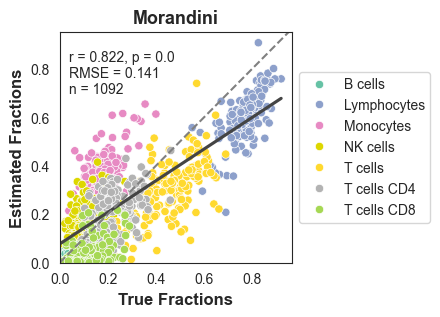

In [38]:

gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
morandini_m = morandini_m.sort_index(key=lambda x: x.str.lower())
evaluation_morandini = helper.create_evaluation_df(gld_m, morandini_m)
rsme_morandini, r_morandini, p_morandini = helper.evaulate_total_df(evaluation_morandini)
rsmes_morandini, ps_morandini, rs_morandini = helper.evaluate_by_cell_type(gld_m, morandini_m)
helper.create_scatter_plot_total(evaluation_morandini, rsme_morandini, p_morandini, r_morandini,
                                 'Morandini', save_path='../figures/fig2a_morandini.pdf', size=(3, 3))

In [ ]:
estimations_altman, signatures_altman = rp.rectangle(adata_hao_sub, bulks_altman.T)

In [41]:
estimations_altman = pd.read_csv('../output/hao_estimations_altman.csv', index_col=0)

estimations_altman['Lymphocytes'] = estimations_altman['T cells CD4 conv'] + estimations_altman['T cells CD8'] + estimations_altman[
    'Tregs'] + estimations_altman['B cells'] + estimations_altman['NK cells'] + estimations_altman['ILC']
estimations_altman['Plasma cells'] = estimations_altman['Lymphocytes'] + estimations_altman['Plasma cells']
estimations_altman['Monocytes'] = estimations_altman['Monocytes'] + estimations_altman['mDC'] + estimations_altman['pDC']
estimations_altman = estimations_altman.T

In [42]:
altman_facs = pd.read_csv('../data/fig2/altman/altman_facs.csv', index_col=0)
altman_facs = altman_facs.T

In [43]:
gld_m, altman_m = helper.match_dfs(altman_facs.T, estimations_altman)

<Axes: title={'center': 'Altman'}, xlabel='True Fractions', ylabel='Estimated Fractions'>

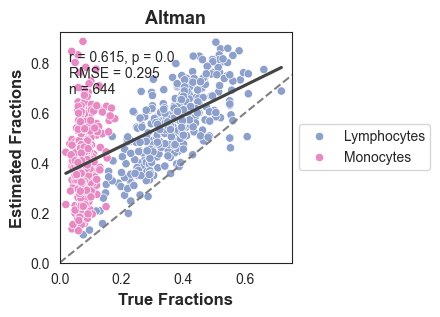

In [44]:
gld_m = gld_m.sort_index(key=lambda x: x.str.lower())
altman_m = altman_m.sort_index(key=lambda x: x.str.lower())
evaluation_altman = helper.create_evaluation_df(gld_m, altman_m)
rsme_altman, r_altman, p_altman = helper.evaulate_total_df(evaluation_altman)
rsmes_altman, ps_altman, rs_altman = helper.evaluate_by_cell_type(gld_m, altman_m)
helper.create_scatter_plot_total(evaluation_altman, rsme_altman, p_altman, r_altman,
                                 'Altman', save_path='../figures/fig2a_altman.pdf', size=(3, 3))

# Figure 2B

In [46]:
corr_df_fino = pd.DataFrame(index=finotello_m.index, data=rs_f_rectangle)
corr_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rs_pept)
corr_df_chen = pd.DataFrame(index=chen_m.T.index, data=rs_chen)
corr_df_hoek = pd.DataFrame(index=hoek_m.index, data=rs_h)
corr_df_morandini = pd.DataFrame(index=morandini_m.index, data=rs_morandini)
corr_df_altman = pd.DataFrame(index=altman_m.index, data=rs_altman)

rmse_df_fino = pd.DataFrame(index=finotello_m.index, data=rsmes_f_rectangle)
rmse_df_pept = pd.DataFrame(index=petitprez_m.T.index, data=rsmes_pept)
rmse_df_chen = pd.DataFrame(index=chen_m.T.index, data=rsmes_chen)
rmse_df_hoek = pd.DataFrame(index=hoek_m.index, data=rsmes_h)

rmse_df_morandini = pd.DataFrame(index=morandini_m.index, data=rsmes_morandini)
rmse_df_altman = pd.DataFrame(index=altman_m.index, data=rsmes_altman)


<Figure size 640x480 with 0 Axes>

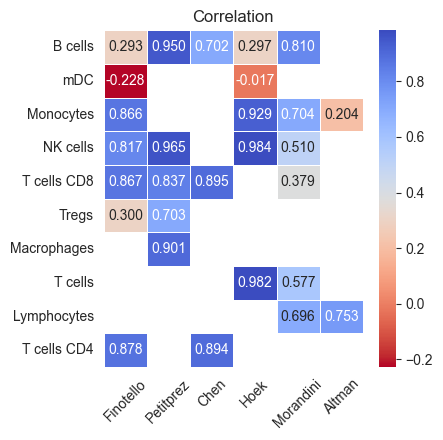

In [50]:
df_cor = pd.concat([corr_df_fino, corr_df_pept, corr_df_chen, corr_df_hoek, corr_df_morandini, corr_df_altman], axis=1)
df_cor.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Altman']
df_cor = df_cor.T
df_cor['T cells CD4'] = df_cor['T cells CD4 Total'].add(df_cor['T cells CD4 conv'], fill_value=0)
df_cor = df_cor.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'])
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatmap
import seaborn as sns
sns.set_style("white")
sns.heatmap(df_cor.T, annot=True, cmap='coolwarm_r', fmt=".3f", linewidths=.5)
plt.title('Correlation')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()

plt.savefig('../figures/fig2b_corr_heat.pdf')

# Display the subplots
plt.show()



<Figure size 640x480 with 0 Axes>

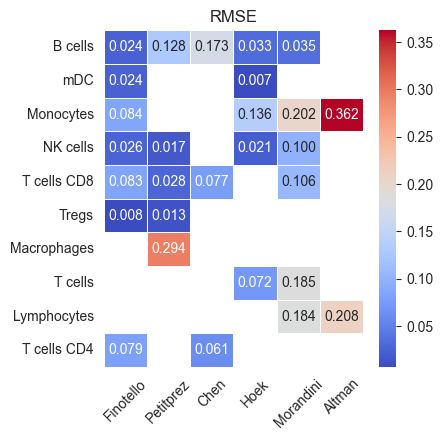

In [52]:
df_rmse = pd.concat([rmse_df_fino, rmse_df_pept, rmse_df_chen, rmse_df_hoek, rmse_df_morandini, rmse_df_altman], axis=1)
df_rmse.columns = ['Finotello', 'Petitprez', 'Chen', 'Hoek', 'Morandini', 'Altman']
df_rmse = df_rmse.T
df_rmse['T cells CD4'] = df_rmse['T cells CD4 Total'].add(df_rmse['T cells CD4 conv'], fill_value=0)
df_rmse = df_rmse.drop(columns=['T cells CD4 Total', 'T cells CD4 conv'])
plt.figure(facecolor='white')
# size
plt.figure(figsize=(4.5, 4.5))
# Plot the first heatma
import seaborn as sns
sns.set_style("white")

sns.heatmap(df_rmse.T, annot=True, cmap='coolwarm', fmt=".3f", linewidths=.5)
plt.title('RMSE')
#rotating the x-axis labels
plt.xticks(rotation=45)


# Adjust spacing between subplots
plt.tight_layout()

plt.savefig('../figures/fig2b_rmse_heat.pdf')

## Fig 2c



In [53]:
all_meths = pd.read_csv('../data/cor_rmse_all.csv', sep=';')
# replace ',' with '.'
all_meths['Correlation'] = all_meths['Cor'].str.replace(',', '.').astype(float)
all_meths['RMSE'] = all_meths['RMSE'].str.replace(',', '.').astype(float)

all_meths_chen = all_meths[all_meths['Set'] == 'Chen']
all_meths_fino = all_meths[all_meths['Set'] == 'Finotello']
all_meths_hoek = all_meths[all_meths['Set'] == 'Hoek']
all_meths_peti = all_meths[all_meths['Set'] == 'Petitprez']
all_meths_morandini = all_meths[all_meths['Set'] == 'Morandini']
all_meths_altman = all_meths[all_meths['Set'] == 'Altman']

In [54]:
method_palette = {
    "autogenes": "#66C2A5",
    "bayesprism": "#FC8D62",
    "bisque": "#8DA0CB",
    "cibersortx": "#E78AC3",
    "dwls": "#A6D854",
    "music": "#FFD92F",
    "scaden": "#E5C494",
    "scdc": "#B3B3B3",
    "rectangle": "#000000"
}

color_palette = [method_palette[key] for key in method_palette]

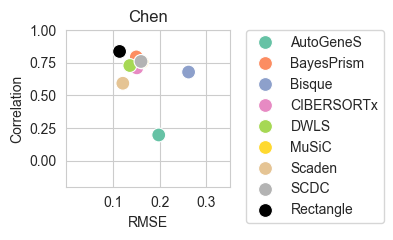

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# style white with ticks
sns.set_style("whitegrid")


plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_chen, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Chen')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)
#include ticks
# move the legend
#horizantal legend
#tight layout

plt.savefig('../figures/fig2c_chen.pdf')
plt.show()

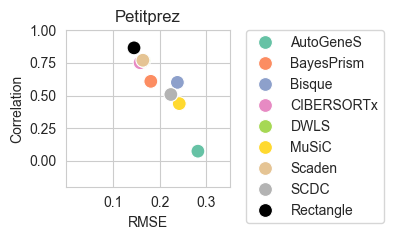

In [23]:
sns.set_style("whitegrid")


plt.figure(figsize=(2.5, 2.5))

sns.scatterplot(data=all_meths_peti, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Petitprez')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

# set y axis limits
plt.tight_layout()
# move the legend
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_petitprez.pdf')
plt.show()

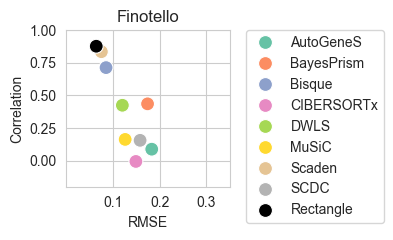

In [25]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_fino, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Finotello')
plt.ylim(-0.20, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()

plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)

plt.savefig('../figures/fig2c_fino.pdf')
plt.show()

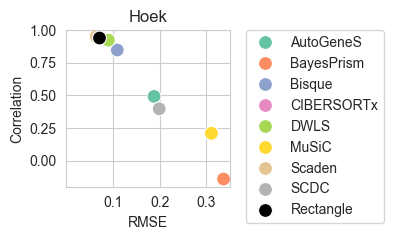

In [26]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_hoek, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Hoek')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
# some more x ticks
plt.xticks([0.1, 0.2, 0.3])

#legend title
plt.tight_layout()

# move the legend
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)
#tight layout
plt.savefig('../figures/fig2c_hoek.pdf')
plt.show()


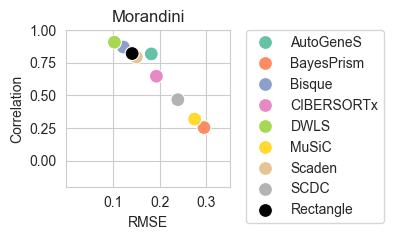

In [66]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_morandini, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Morandini')
plt.ylim(-0.2, 1)
plt.xlim(0, 0.35)
plt.xticks([0.1, 0.2, 0.3])

plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_morandini.pdf')
plt.show()

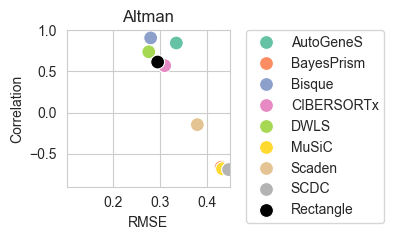

In [76]:
plt.figure(figsize=(2.5, 2.5))
sns.scatterplot(data=all_meths_altman, x='RMSE', y='Correlation', hue='Method', s=100, palette=color_palette)
plt.title('Altman')
plt.ylim(-0.9, 1)
plt.xlim(0.1, 0.45)
plt.xticks([0.2, 0.3, 0.4])
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.10, 1), loc=2, borderaxespad=0.)#tight layout
plt.savefig('../figures/fig2c_altman.pdf')
plt.show()